# Sistem Rekomendasi Laptop
### User-Based Collaborative Filtering + Cold Start Handling
---

## 1. Pembacaan Data dan Preprocessing

In [ ]:
import pandas as pd
import numpy as np

# Membaca dataset laptop yang sudah melalui proses clustering
df_laptop = pd.read_csv('whole_cluster_laptops.csv')

# Membaca dataset ulasan pengguna Amazon (berisi user_id, rating, parent_asin)
df_user = pd.read_csv('amazon_laptop_reviews.csv')

# Membaca dataset fitur inti laptop sebelum dinormalisasi (price, RAM, Hard Drive, brand, CPU)
df_laptopCore = pd.read_csv('laptop_features_coreData.csv')

display(df_laptop)

,parent_asin,Brand,Ram,price,Hard Drive,CPU Model,Cluster
0,B003M6SN8U,3,0.096774,0.212799,0.237805,1,0
1,B003WUXMVY,0,0.032258,0.212799,0.110772,1,0
2,B004LB4A82,20,0.032258,0.212799,0.174289,2,5
3,B004PANKIA,6,0.032258,0.212799,0.110772,1,3
4,B0052F35I2,6,0.064516,0.212799,0.146341,2,3
...,...,...,...,...,...,...,...
1642,B0CG7MS49B,13,0.096774,0.184646,0.113821,2,2
1643,B0CG99HKK6,6,0.096774,0.117833,0.113821,1,3
1644,B0CH7T15G8,17,0.225806,0.246840,0.237805,2,1
1645,B0CHB37Y85,13,0.048387,0.168854,0.237805,5,6


In [ ]:
# Mengambil hanya kolom yang diperlukan dari dataset ulasan pengguna
# Kolom yang diambil: rating (nilai ulasan), parent_asin (id laptop), user_id (id pengguna)

df_user_selected = df_user[['rating', 'parent_asin', 'user_id']]

display(df_user_selected)

,rating,parent_asin,user_id
0,5,B08G5F3X8F,AHV6QCNBJNSGLATP56JAWJ3C4G2A
1,5,B08G5F3X8F,AFNC5IF4WHTXND7NFTXIKBHQKZ7A
2,5,B08G5F3X8F,AFOPOR5RN7JTWVXC72ITV7XJXIXA
3,1,B08G5F3X8F,AEQBZ7WR6AYATE3WRWD2LVD74FOA
4,1,B08G5F3X8F,AGLZUC53J6SZNIXLOECZ7GOIZFNQ
...,...,...,...
32754,5,B06XRXZN33,AFBVMHIHHS4KAVHBP4S6KCEY3GHQ
32755,5,B06XRXZN33,AFBVMHIHHS4KAVHBP4S6KCEY3GHQ
32756,5,B07SLY46H2,AFFWV4ESOC5DPNXGIOPX4S53EIEQ
32757,1,B08DFZH8V8,AGG3QJNLLAZGVWURAIHHODDS4DJQ


In [ ]:
# Menyimpan jumlah baris sebelum proses filtering sebagai pembanding
before = len(df_user_selected)

# Memfilter df_user_selected agar hanya menyimpan rating untuk laptop
# yang parent_asin-nya terdapat pada df_laptop (laptop yang sudah di-cluster)
# Ini memastikan konsistensi data antara tabel rating dan tabel laptop

df_user_selected = df_user_selected[
    df_user_selected['parent_asin'].isin(df_laptop['parent_asin'])
].reset_index(drop=True)

# reset index agar kembali mulai dari 0

# Menyimpan jumlah baris setelah filtering
after = len(df_user_selected)

# Menampilkan laporan jumlah data yang terhapus dan sisa data yang tersedia
print('Data terhapus:', before - after)
print('Sisa data    :', after)

Data terhapus: 6750
Sisa data    : 26009


---
## 2. Pembentukan Matriks User-Item (Sparse Matrix)

In [ ]:
from scipy.sparse import coo_matrix

# Membuat salinan dataset agar data asli tidak berubah selama proses selanjutnya
df_reviews = df_user_selected.copy()

# Mengonversi user_id dan parent asin menjadi kode numerik kategori (0, 1,2..)
user_codes = df_reviews['user_id'].astype('category').cat.codes # baris
item_codes = df_reviews['parent_asin'].astype('category').cat.codes # kolom

# Mengambil nilai rating sebagai isi (nilai) dari matriks
ratings = df_reviews['rating']

# Membuat User-Item matrix dalam format COO (Coordinate) lalu dikonversi ke CSR
# COO efisien untuk konstruksi awal, CSR efisien untuk operasi akses baris (slicing)

user_item_matrix = coo_matrix(
    (ratings, (user_codes, item_codes))
).tocsr()

# Menampilkan ukuran dan jumlah rating tersimpan di dalam sparse matrix
print('Shape matrix         :', user_item_matrix.shape)
print('Jumlah rating tersimpan:', user_item_matrix.nnz)
print(user_item_matrix[:20])

Shape matrix         : (25174, 1647)
Jumlah rating tersimpan: 25679
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 20 stored elements and shape (20, 1647)>
  Coords	Values
  (0, 374)	4
  (1, 1537)	2
  (2, 1589)	4
  (3, 1511)	5
  (4, 1527)	5
  (5, 859)	5
  (6, 1231)	5
  (7, 1587)	5
  (8, 851)	5
  (9, 851)	5
  (10, 179)	2
  (11, 423)	5
  (12, 563)	2
  (13, 1608)	5
  (14, 1645)	4
  (15, 504)	1
  (16, 595)	5
  (17, 725)	3
  (18, 1522)	5
  (19, 647)	5


In [ ]:
# Membuat mapping dari indeks numerik ke user_id asli (index -> user_id)
# Digunakan untuk menampilkan hasil rekomendasi dengan identitas asli pengguna
user_mapping = dict(
    enumerate(df_reviews['user_id'].astype('category').cat.categories)
)

# Membuat mapping dari indeks numerik ke parent_asin asli (index -> parent_asin)
# Digunakan untuk menampilkan hasil rekomendasi dengan identitas laptop yang sesungguhnya
item_mapping = dict(
    enumerate(df_reviews['parent_asin'].astype('category').cat.categories)
)

# Membalik user_mapping menjadi user_id -> index
# Digunakan untuk mencari indeks baris dari user_id yang diinput pengguna
user_to_index = {v: k for k, v in user_mapping.items()}

---
## 3. Collaborative Filtering: Mencari User Mirip dan Rekomendasi Item

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

def get_similar_users(user_index, user_item_matrix, top_k=5):
    # Mengambil vektor rating pengguna target (baris ke-user_index dari matriks)
    user_vector = user_item_matrix[user_index]

    # Menghitung cosine similarity antara vektor pengguna target dan semua pengguna lain
    # Hasil flatten() mengubah matriks 1xN menjadi array 1 dimensi
    similarities = cosine_similarity(user_vector, user_item_matrix).flatten()

    # Mengurutkan indeks dari similarity tertinggi ke terendah,
    # lalu mengambil top-K mulai dari indeks ke-1 (indeks ke-0 adalah diri sendiri)
    similar_users = similarities.argsort()[::-1][1:top_k + 1]

    # Mengembalikan indeks pengguna mirip beserta nilai similarity-nya
    return similar_users, similarities[similar_users]

# Prediksi Rating

In [ ]:
def recommend_items(user_index, user_item_matrix, similar_users, scores, top_n=5):

    # Mengambil data rating pengguna yang sedang dicari rekomendasinya
    user_vector = user_item_matrix[user_index].toarray().flatten()

    # Mengambil data rating dari pengguna yang paling kemiripan
    similar_matrix = user_item_matrix[similar_users].toarray()

    # Menghitung total nilai rating setiap item
    # Rating asli dikalikan dengan nilai similaritynya
    weighted_sum = np.dot(scores, similar_matrix)

    # Menandai item yang pernah diberi rating oleh pengguna mirip
    # Nilai 1 = pernah dirating, 0 = belum dirating
    rated_mask = (similar_matrix > 0).astype(float)

    # Menjumlahkan nilai similarity hanya untuk pengguna yang merating item tersebut (per item)
    sum_similarity_per_item = np.dot(scores, rated_mask)
    predicted_ratings = np.where(
        sum_similarity_per_item > 0,
        weighted_sum / sum_similarity_per_item,
        0)

    # Menghapus item yang sudah pernah dirating oleh pengguna target
    predicted_ratings[user_vector > 0] = 0

    # Mencari item yang memiliki nilai prediksi lebih dari 0
    # Item-item ini menjadi calon rekomendasi
    candidate_items = np.where(predicted_ratings > 0)[0]

    # Jika tidak ada item yang bisa direkomendasikan
    if len(candidate_items) == 0:
        return [], []

    # Mengambil nilai prediksi rating hanya untuk kandidat item
    candidate_scores = predicted_ratings[candidate_items]

    # Mengurutkan item berdasarkan nilai prediksi tertinggi
    # Kemudian mengambil sejumlah top_n item terbaik
    top_indices = candidate_scores.argsort()[::-1][:top_n]

    # Mengembalikan indeks item rekomendasi dan nilai prediksinya
    return candidate_items[top_indices], candidate_scores[top_indices]

# Test Collaborative

In [ ]:
# target_user_id = df_reviews['user_id'].iloc[0]
target_user_id = "AGMUGS6Z2QOB43LZSQDZYZSZRKQA"

# Mengambil index numerik dari target_user_id
user_index = user_to_index[target_user_id]

# memanggil method get_similar_users untuk mencari user yang sama sesuai dengan user_index pada matrix
similar_users, scores = get_similar_users(
    user_index, user_item_matrix, top_k=5)

# Tampilkan
print("User target:", target_user_id)
similar_users_df = pd.DataFrame({'User_id': [user_mapping[idx] for idx in similar_users],'similarity': scores})
display(similar_users_df)

User target: AGMUGS6Z2QOB43LZSQDZYZSZRKQA


,User_id,similarity
0,AED6G6RZDEIMXSJOMFX6QNXY34OA,0.573819
1,AFEU7Z4XXQAYTIMY5XSVZGRBQ6TA,0.552158
2,AEV3QTYJOSBLEYTDWDLVAPVZJ5KQ,0.552158
3,AGNRO4NYAHHDATEC5R5PWCVRV3MQ,0.552158
4,AHHYX3K3SAD76N2TZODBP2XZMTIQ,0.552158


In [ ]:
# memanggil method collaborative filltering
recommended_items, item_scores = recommend_items(user_index,user_item_matrix,similar_users,scores,top_n=5)

/tmp/ipykernel_570/638864202.py:25: RuntimeWarning: invalid value encountered in divide
  weighted_sum / sum_similarity_per_item,


In [ ]:
print("\nRekomendasi untuk user:", target_user_id)

# hasil laptop id yang didapatkan dan prediksi item dijadikan dataframe dengan nama cf_recommendations

cf_recommendations = pd.DataFrame({
    'Laptops_id': [item_mapping[idx] for idx in recommended_items],
    'prediksi_CF': item_scores})

# tampilkan cf_recommendations
display(cf_recommendations)


Rekomendasi untuk user: AGMUGS6Z2QOB43LZSQDZYZSZRKQA


,Laptops_id,prediksi_CF
0,B09YVTK8LN,5.0


---
## 4. Cold Start: Rekomendasi untuk Pengguna Baru

In [ ]:
# Membuat User-Item matrix dalam bentuk pivot table (dense DataFrame)
# index = user_id, columns = parent_asin, values = rating, NaN diisi 0
# Digunakan pada proses Cold Start untuk menghitung rata-rata rating per item per cluster
user_item_df = df_user_selected.pivot_table(index='user_id',
    columns='parent_asin', values='rating').fillna(0)

# Mengambil nilai matriks sebagai array NumPy untuk perhitungan vektor
user_matrix = user_item_df.values
# Menyimpan daftar user_id sebagai list (urutan baris matriks)
user_ids = user_item_df.index.tolist()
# Menyimpan daftar parent_asin sebagai list (urutan kolom matriks)
item_asins = user_item_df.columns.tolist()
# Membuat mapping user_id -> indeks baris untuk pencarian cepat di matrix
user_to_idx = {uid: i for i, uid in enumerate(user_ids)}

In [ ]:
from scipy.spatial.distance import euclidean

def print_separator():
    """Mencetak garis pemisah untuk memperindah tampilan output."""
    print('=' * 70)

# Method masalah cold start
def coldStartProblem(userid, user_preferences):
    print_separator()
    print(f'User: {userid}')
    print('Menghitung kemiripan preferensi user dengan laptop menggunakan Euclidean Distance...')
    print_separator()

    # Mendefinisikan fitur laptop yang akan dibandingkan dengan preferensi pengguna
    feature_cols = ['price', 'Ram', 'Hard Drive', 'Brand', 'CPU Model']

    # Mengonversi list preferensi pengguna menjadi array NumPy untuk perhitungan jarak
    user_pref_array = np.array(user_preferences)

    # Mengambil kolom fitur dari seluruh laptop yang ada di df_laptop
    laptop_features_df = df_laptop[feature_cols]

    # Menghitung jarak Euclidean antara vektor preferensi pengguna
    # dan vektor fitur setiap laptop, lalu menyimpannya ke dalam list distances
    distances = []
    for index, row in laptop_features_df.iterrows():
        dist = euclidean(user_pref_array, row.values)
        distances.append(dist)

    # Menemukan indeks laptop dengan jarak Euclidean terkecil (paling mirip)
    most_similar_laptop_idx = np.argmin(distances)

    # Mengambil label cluster dari laptop yang paling mirip dengan preferensi pengguna
    predicted_cluster = df_laptop.iloc[most_similar_laptop_idx]['Cluster']
    print(f'User {userid} diprediksi cocok pada Cluster: {predicted_cluster}')

    # Memanggil fungsi recommend_new_user untuk menghasilkan rekomendasi
    # berdasarkan cluster yang telah ditentukan
    hasil = recommend_new_user(predicted_cluster)
    return hasil


def recommend_new_user(cluster_id, n=10):
    """
    Merekomendasikan top-N laptop untuk pengguna baru berdasarkan cluster,
    menggunakan rata-rata rating dari seluruh pengguna yang pernah merating laptop tersebut
    (popularity-based recommendation dalam satu cluster).

    Parameter:
        cluster_id : id cluster hasil prediksi coldStartProblem
        n          : jumlah rekomendasi yang akan dikembalikan

    Return:
        list top-N tuple (parent_asin, avg_rating) diurutkan dari rata-rata rating tertinggi
    """
    # Mengambil semua laptop yang termasuk ke dalam cluster_id
    cluster_items = df_laptop[df_laptop['Cluster'] == cluster_id]['parent_asin']

    # Dictionary untuk menyimpan pasangan item: rata-rata rating
    scores = {}

    for item in cluster_items:
        # Melewati item jika tidak tersedia di dalam pivot table item_asins
        if item not in item_asins:
            continue

        # Mengambil indeks kolom item dari pivot table
        item_idx = item_asins.index(item)

        # Mengambil semua nilai rating pada kolom item_idx dari seluruh pengguna
        ratings_col = user_matrix[:, item_idx]

        # Menyaring hanya rating yang valid (lebih dari 0, karena 0 = belum merating)
        valid_ratings = ratings_col[ratings_col > 0]

        # Menghitung dan menyimpan rata-rata rating jika ada pengguna yang pernah merating
        if len(valid_ratings) > 0:
            scores[item] = valid_ratings.mean()

    # Mengurutkan item berdasarkan rata-rata rating dari tertinggi ke terendah
    recs = sorted(scores.items(), key=lambda x: x[1], reverse=True)

    # Mengembalikan top-N rekomendasi
    return recs[:n]

---
## 5. Persiapan Normalisasi dan Encoding untuk Input Preferensi

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Membuat mapping dari nama brand asli ke nilai numerik yang tersimpan di df_laptop
# Contoh: {'Acer': 0, 'Asus': 1, ...}
brand_mapping = dict(zip(df_laptopCore['brand'], df_laptop['Brand']))

# Membuat mapping dari nama CPU asli ke nilai numerik yang tersimpan di df_laptop
# Contoh: {'Core i5': 2, 'Ryzen 5': 4, ...}
cpu_mapping = dict(zip(df_laptopCore['CPU_Model'], df_laptop['CPU Model']))

# Membuat objek MinMaxScaler untuk menormalisasi nilai harga ke rentang [0, 1]
scaler_price = MinMaxScaler()

# Membuat objek MinMaxScaler untuk menormalisasi nilai RAM ke rentang [0, 1]
scaler_ram   = MinMaxScaler()

# Membuat objek MinMaxScaler untuk menormalisasi nilai Hard Drive ke rentang [0, 1]
scaler_hd    = MinMaxScaler()

# Melatih (fit) scaler menggunakan data dari df_laptopCore agar
# transformasi preferensi pengguna konsisten dengan rentang nilai fitur laptop
scaler_price.fit(df_laptopCore[['price']])
scaler_ram.fit(df_laptopCore[['RAM']])
scaler_hd.fit(df_laptopCore[['Hard_Drive']])

MinMaxScaler()

-
## 6. Evaluasi Model: Leave-One-Out (LOO) dengan MAE dan RMSE

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Membalik item_mapping (index -> parent_asin) menjadi item_to_index (parent_asin -> index)
# Digunakan sebagai parameter pada fungsi evaluasi
item_to_index = {v: k for k, v in item_mapping.items()}

# Prediksi rating
def predict_rating_for_user_item(user_index, item_index, user_item_matrix_loo,
                                  similar_users, scores, global_mean_rating):
    """
    Memprediksi rating seorang pengguna untuk satu item tertentu
    berdasarkan weighted average rating dari pengguna-pengguna mirip.
    Digunakan khusus dalam proses evaluasi Leave-One-Out.

    Parameter:
        user_index            : indeks pengguna target
        item_index            : indeks item yang diprediksi
        user_item_matrix_loo  : salinan matriks dengan rating item yang sedang diuji dihapus
        similar_users         : array indeks pengguna mirip
        scores                : array nilai cosine similarity pengguna mirip
        global_mean_rating    : rata-rata rating global sebagai fallback jika prediksi tidak bisa dihitung

    Return:
        nilai prediksi rating (float)
    """
    # Validasi: jika item_index melebihi jumlah kolom matriks, kembalikan rata-rata global
    if item_index >= user_item_matrix_loo.shape[1]:
        return global_mean_rating

    # Mengambil rating item yang sedang diuji dari seluruh pengguna mirip
    # Hasilnya berupa array 1D: satu nilai per pengguna mirip
    similar_users_ratings_for_item = (
        user_item_matrix_loo[similar_users, item_index]
        .toarray()
        .flatten()
    )

    # Menghitung weighted sum: jumlah (similarity * rating) untuk setiap pengguna mirip
    weighted_sum_ratings = np.dot(scores, similar_users_ratings_for_item)

    # Membuat mask biner: 1 jika pengguna mirip merating item ini, 0 jika tidak
    rated_mask = (similar_users_ratings_for_item > 0).astype(float)

    # Menjumlahkan similarity hanya dari pengguna yang benar-benar merating item ini
    sum_similarity_per_item = np.dot(scores, rated_mask)

    # Jika tidak ada pengguna mirip yang pernah merating item ini, kembalikan rata-rata global
    if sum_similarity_per_item == 0:
        return global_mean_rating

    # Menghitung prediksi rating dengan rumus weighted average
    predicted_rating = weighted_sum_ratings / sum_similarity_per_item

    return predicted_rating

# MAE DAN RMSE DISINI

def evaluate_model_loo(user_item_matrix, user_to_index, item_to_index,
                        get_similar_users_func, k_similar=10):
    """
    Mengevaluasi akurasi model menggunakan metode Leave-One-Out (LOO).
    Untuk setiap pasangan (user, item), rating tersebut dihapus sementara,
    lalu prediksi dilakukan dan dibandingkan dengan rating aslinya.

    Parameter:
        user_item_matrix       : sparse matrix User-Item dalam format CSR
        user_to_index          : mapping user_id -> indeks numerik
        item_to_index          : mapping parent_asin -> indeks numerik
        get_similar_users_func : fungsi untuk mencari pengguna mirip
        k_similar              : jumlah pengguna mirip yang digunakan

    Return:
        mae  : Mean Absolute Error
        rmse : Root Mean Squared Error
    """
    # Menghitung rata-rata rating global dari semua rating yang tersimpan
    # Digunakan sebagai nilai fallback ketika prediksi tidak bisa dihitung
    global_mean_rating = np.mean(user_item_matrix.data)

    # List untuk menyimpan semua pasangan (rating asli, rating prediksi)
    actual_ratings    = []
    predicted_ratings = []

    # Mengambil total jumlah pengguna dari jumlah baris matriks
    num_users = user_item_matrix.shape[0]

    # Penghitung total pasangan yang berhasil dievaluasi
    total_evaluations = 0

    # Iterasi untuk setiap pengguna dalam matriks
    for u_idx in range(num_users):

        # Mengambil indeks kolom (item) yang pernah diberi rating oleh pengguna ini
        rated_items_indices = user_item_matrix[u_idx].nonzero()[1]

        # Melewati pengguna yang tidak memiliki rating sama sekali
        if len(rated_items_indices) == 0:
            continue

        # Iterasi LOO: uji setiap item yang pernah di-rating satu per satu
        for i_idx in rated_items_indices:

            # Menyimpan nilai rating asli sebelum dihapus
            actual_rating = user_item_matrix[u_idx, i_idx]

            # Membuat salinan matriks untuk proses LOO
            # (matriks asli tidak boleh diubah agar evaluasi setiap item bersifat independen)
            user_item_matrix_loo = user_item_matrix.copy()

            # Menghapus sementara rating item yang sedang diuji (dijadikan 0)
            user_item_matrix_loo[u_idx, i_idx] = 0

            # Mencari pengguna mirip menggunakan matriks LOO (tanpa rating yang diuji)
            similar_users, sim_scores = get_similar_users_func(
                u_idx, user_item_matrix_loo, top_k=k_similar
            )

            # Memprediksi rating untuk item yang sedang diuji menggunakan pengguna mirip
            predicted_r = predict_rating_for_user_item(
                u_idx, i_idx, user_item_matrix_loo,
                similar_users, sim_scores, global_mean_rating
            )

            # Menyimpan pasangan rating asli dan prediksi ke dalam list
            actual_ratings.append(float(actual_rating))
            predicted_ratings.append(predicted_r)

            # Menambah penghitung evaluasi
            total_evaluations += 1

    # Jika tidak ada pasangan yang berhasil dievaluasi, tampilkan pesan dan kembalikan 0
    if total_evaluations == 0:
        print('Tidak ada pasangan aktual/prediksi yang valid untuk evaluasi.')
        return 0, 0

    # Menghitung MAE: rata-rata perbedaan absolut antara rating asli dan prediksi
    mae  = mean_absolute_error(actual_ratings, predicted_ratings)

    # Menghitung RMSE: akar rata-rata kuadrat selisih rating asli dan prediksi
    rmse = np.sqrt(mean_squared_error(actual_ratings, predicted_ratings))

    return mae, rmse

---
## 7. Main Program: Sistem Rekomendasi Interaktif


MENU REKOMENDASI
1. Dapatkan Rekomendasi
2. Evaluasi Rekomendasi
3. Keluar
Pilih opsi (1/2/3): 1

MEMPROSES REKOMENDASI
Masukkan user id: USEBARUMARIA

[INFO] User baru terdeteksi (Cold Start). Silakan input preferensi awal.
Masukkan budget harga (contoh 1000): 500
Masukkan RAM yang diinginkan (contoh 8): 4
Masukkan Hard Drive yang diinginkan (contoh 512): 512

Daftar Brand:
--------------------
- Apple
- ASUS
- Samsung
- Dell
- Sony
- Msi
- Acer
- HP
- Lenovo
- Alienware
- GIGABYTE
- Computer Upgrade King
- Razer
- Eluktronics
- Microsoft
- Toshiba
- Ibuypower
- Cyberpowerpc
- Lg
- Powerspec
- Evoo
- Maingear
- Dynabook

Masukkan Brand (contoh Acer): Dell

Daftar CPU:
--------------------
- Core i5
- Core i7
- Core i3
- Core i9
- Ryzen 5
- Ryzen 7
- Ryzen 9
- Ryzen 3

Masukkan CPU Model (contoh Core i5): Core i5

------------------------------------------------------------
HASIL PREFERENCE SETELAH NORMALISASI:
[0.07677375309463824, 0.03225806451612903, 0.11382113821138212, 6, 1]
User

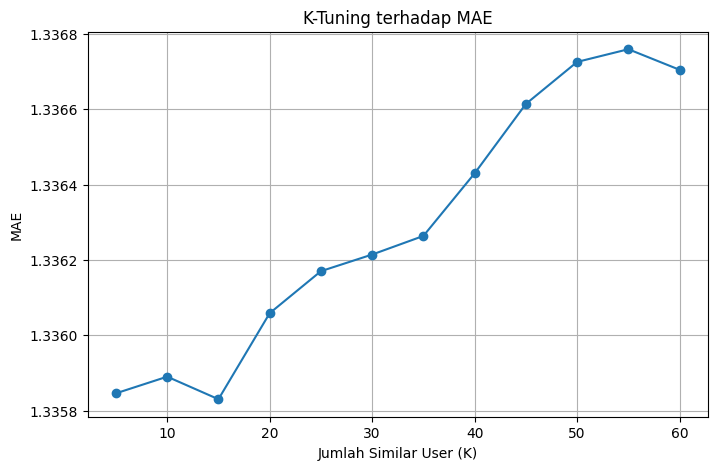

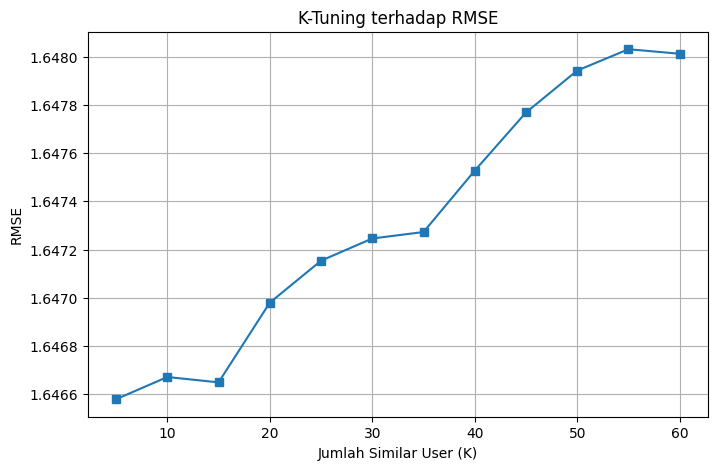


MENU REKOMENDASI
1. Dapatkan Rekomendasi
2. Evaluasi Rekomendasi
3. Keluar
Pilih opsi (1/2/3): 3

Terima kasih! Program selesai.


In [ ]:
import warnings
warnings.filterwarnings('ignore')  # Menyembunyikan peringatan agar output lebih bersih

import matplotlib.pyplot as plt

def normalize_text(text):
    """
    Menormalisasi teks input pengguna menjadi huruf kecil tanpa spasi berlebih.
    Digunakan agar pencocokan brand dan CPU tidak case-sensitive.
    """
    return text.lower().strip()

# Input preferensi user
def get_user_preferences_manual(df_laptopCore, brand_mapping_lower, cpu_mapping_lower,
                                 scaler_price, scaler_ram, scaler_hd):
    try:
        # Meminta input harga, RAM, dan Hard Drive dari pengguna
        price_input = float(input('Masukkan budget harga (contoh 1000): '))
        ram_input   = int(input('Masukkan RAM yang diinginkan (contoh 8): '))
        hd_input    = int(input('Masukkan Hard Drive yang diinginkan (contoh 512): '))

        # Menampilkan daftar brand yang tersedia agar pengguna bisa memilih dengan tepat
        print('\nDaftar Brand:')
        print('-' * 20)
        for b in df_laptopCore['brand'].unique():
            print(f'- {b}')

        # Validasi input brand: terus meminta input hingga brand yang valid ditemukan
        while True:
            brand_input      = input('\nMasukkan Brand (contoh Acer): ')
            brand_input_norm = normalize_text(brand_input) # normalisasi ke huruf kecil
            if brand_input_norm in brand_mapping_lower:
                brand_pref = brand_mapping_lower[brand_input_norm]  #label encoding ke nilai numerik
                break
            print('[ERROR] Brand tidak ditemukan! Coba lagi.')

        # Menampilkan daftar CPU yang tersedia agar pengguna bisa memilih dengan tepat
        print('\nDaftar CPU:')
        print('-' * 20)
        for c in df_laptopCore['CPU_Model'].unique():
            print(f'- {c}')

        # Validasi input CPU: terus meminta input hingga CPU yang valid ditemukan
        while True:
            cpu_input      = input('\nMasukkan CPU Model (contoh Core i5): ')
            cpu_input_norm = normalize_text(cpu_input)  # normalisasi ke huruf kecil
            if cpu_input_norm in cpu_mapping_lower:
                cpu_model_pref = cpu_mapping_lower[cpu_input_norm]  # encode ke nilai numerik
                break
            print('[ERROR] CPU Model tidak ditemukan! Coba lagi.')

        # Normalisasi preferensi user nilai numerik (harga, RAM, Hard Drive) menggunakan MinMaxScaler
        price_pref      = scaler_price.transform([[price_input]])[0][0]
        ram_pref        = scaler_ram.transform([[ram_input]])[0][0]
        hard_drive_pref = scaler_hd.transform([[hd_input]])[0][0]

        # Menyusun vektor preferensi pengguna yang sudah ternormalisasi dan diencode
        user_preferences = [
            float(price_pref),
            float(ram_pref),
            float(hard_drive_pref),
            int(brand_pref),
            int(cpu_model_pref)
        ]

        # Menampilkan vektor preferensi setelah normalisasi untuk konfirmasi
        print('\n' + '-' * 60)
        print('HASIL PREFERENCE SETELAH NORMALISASI:')
        print(user_preferences)

        return user_preferences

    except ValueError:
        # Menangkap kesalahan jika pengguna memasukkan nilai bukan angka
        print('[ERROR] Input angka tidak valid.')
        return None


def tampilkan_rekomendasi(df, title):
    """
    Menampilkan hasil rekomendasi dalam format tabel yang rapi.

    Parameter:
        df    : DataFrame berisi hasil rekomendasi
        title : judul yang ditampilkan di atas tabel
    """
    print('\n' + '=' * 60)
    print(title)
    print('=' * 60)
    print(df.to_string(index=False))
    print('=' * 60)


# Membuat versi mapping brand dan CPU dalam huruf kecil
# agar pencocokan input pengguna tidak case-sensitive
brand_mapping_lower = {k.lower(): v for k, v in brand_mapping.items()}
cpu_mapping_lower   = {k.lower(): v for k, v in cpu_mapping.items()}


# ============================================================
# MAIN LOOP: Program berjalan terus sampai pengguna memilih keluar
# ============================================================
while True:
    print('\n' + '=' * 60)
    print('MENU REKOMENDASI')
    print('1. Dapatkan Rekomendasi')
    print('2. Evaluasi Rekomendasi')
    print('3. Keluar')
    print('=' * 60)

    choice = input('Pilih opsi (1/2/3): ')

    # ----------------------------------------------------------
    # MENU 1: REKOMENDASI
    # ----------------------------------------------------------
    if choice == '1':
        print('\n' + '=' * 60)
        print('MEMPROSES REKOMENDASI')
        print('=' * 60)

        # Meminta user_id dari pengguna
        User_id = input('Masukkan user id: ')

        # ======================================================
        # SKENARIO 1: USER LAMA (sudah ada di sistem)
        # ======================================================
        if User_id in user_to_index:
            user_index = user_to_index[User_id]  # ambil indeks numerik dari user_id

            print(f'\n[INFO] User ditemukan (user lama): {User_id}')
            print('Memproses rekomendasi...\n')

            # Mencari 10 pengguna paling mirip menggunakan Cosine Similarity

            similar_users, scores = get_similar_users(
                user_index, user_item_matrix, top_k=10
            )

            # Menghasilkan top-5 rekomendasi laptop menggunakan Collaborative Filtering
            recommended_items, item_scores = recommend_items(
                user_index, user_item_matrix, similar_users, scores, top_n=5
            )

            # --- Jika CF berhasil menghasilkan rekomendasi ---
            if len(recommended_items) > 0:
                # Menyusun DataFrame rekomendasi dengan parent_asin dan skor prediksi
                cf_df = pd.DataFrame({
                    'Laptops_id' : [item_mapping[idx] for idx in recommended_items],
                    'prediksi_CF': item_scores
                })
                tampilkan_rekomendasi(cf_df, f" REKOMENDASI UNTUK USER '{User_id}'")

            # --- Jika CF tidak menghasilkan rekomendasi (fallback ke Cold Start) ---
            else:
                print('[INFO] Tidak ada rekomendasi dari CF, beralih ke metode Cold Start.')

                # Mengambil semua item yang pernah di-rating oleh pengguna dari sparse matrix
                user_row = user_item_matrix[user_to_index[User_id]]
                user_rated_items = {
                    item_mapping[idx]: rating
                    for idx, rating in zip(user_row.indices, user_row.data)
                }

                # Menyaring item yang mendapat rating tinggi (>= 4) dari pengguna ini
                high_rated_items = {
                    asin: rating
                    for asin, rating in user_rated_items.items()
                    if rating >= 4
                }

                # --- Jika ada item dengan rating tinggi, gunakan fiturnya sebagai preferensi ---
                if high_rated_items:
                    # Mengambil item dengan rating paling tinggi
                    best_item_asin = max(high_rated_items, key=high_rated_items.get)

                    # Memastikan item tersebut ada di kedua dataset (df_laptop dan df_laptopCore)
                    if (not df_laptop[df_laptop['parent_asin'] == best_item_asin].empty and
                            not df_laptopCore[df_laptopCore['parent_asin'] == best_item_asin].empty):

                        best_laptop = df_laptop[df_laptop['parent_asin'] == best_item_asin].iloc[0]
                        best_core   = df_laptopCore[df_laptopCore['parent_asin'] == best_item_asin].iloc[0]

                        # Menyusun vektor preferensi dari fitur laptop dengan rating tertinggi
                        user_preferences = [
                            float(scaler_price.transform([[best_core['price']]])[0][0]),
                            float(scaler_ram.transform([[best_core['RAM']]])[0][0]),
                            float(scaler_hd.transform([[best_core['Hard_Drive']]])[0][0]),
                            int(best_laptop['Brand']),
                            int(best_laptop['CPU Model'])
                        ]
                        print('[INFO] Preferensi diambil otomatis dari laptop dengan rating >= 4.')

                    else:
                        # Jika data laptop tidak ditemukan, minta input manual
                        print('[INFO] Data laptop tidak ditemukan, gunakan input manual.')
                        user_preferences = get_user_preferences_manual(
                            df_laptopCore, brand_mapping_lower, cpu_mapping_lower,
                            scaler_price, scaler_ram, scaler_hd
                        )

                # --- Jika tidak ada item dengan rating tinggi, minta input manual ---
                else:
                    print('[INFO] Tidak ada rating >= 4, silakan input preferensi secara manual.')
                    user_preferences = get_user_preferences_manual(
                        df_laptopCore, brand_mapping_lower, cpu_mapping_lower,
                        scaler_price, scaler_ram, scaler_hd
                    )

                # Menjalankan Cold Start dan menampilkan hasil rekomendasi fallback
                if user_preferences:
                    cold_start_recs = coldStartProblem(User_id, user_preferences)
                    if cold_start_recs:
                        cold_df = pd.DataFrame(cold_start_recs, columns=['Laptops_id', 'Popularity_based'])
                        cold_df['Popularity_based'] = cold_df['Popularity_based'].round(2)
                        tampilkan_rekomendasi(cold_df, f" REKOMENDASI FALLBACK UNTUK USER '{User_id}'")

        # ======================================================
        # SKENARIO 2: USER BARU (belum ada di sistem / cold start)
        # ======================================================
        else:
            print('\n[INFO] User baru terdeteksi (Cold Start). Silakan input preferensi awal.')
            # Meminta input preferensi dari pengguna baru secara manual
            user_preferences = get_user_preferences_manual(
                df_laptopCore, brand_mapping_lower, cpu_mapping_lower,
                scaler_price, scaler_ram, scaler_hd)

            # Menjalankan Cold Start dan menampilkan hasil rekomendasi
            if user_preferences:
                cold_start_recs = coldStartProblem(User_id, user_preferences)
                if cold_start_recs:
                    cold_df = pd.DataFrame(cold_start_recs, columns=['Laptops_id', 'Popularity_based'])
                    cold_df['Popularity_based'] = cold_df['Popularity_based'].round(2)
                    tampilkan_rekomendasi(cold_df, f" REKOMENDASI UNTUK USER BARU '{User_id}'")

    elif choice == '2':
        print('\n' + '=' * 60)
        print('     EVALUASI REKOMENDASI')
        print('=' * 60)

        # Menghitung rata-rata rating global
        global_mean_rating = np.mean(user_item_matrix.data)

        # Nilai k yang akan diuji
        k_tuning = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]

        mae_results = []
        rmse_results = []

        print("Melakukan K-Tuning...\n")

        for k in k_tuning:
            print(f"Evaluasi k = {k}")

            mae, rmse = evaluate_model_loo(
                user_item_matrix=user_item_matrix,
                user_to_index=user_to_index,
                item_to_index=item_to_index,
                get_similar_users_func=get_similar_users,
                k_similar=k)

            mae_results.append(mae)
            rmse_results.append(rmse)

            print(f"MAE  : {mae:.4f}")
            print(f"RMSE : {rmse:.4f}")
            print("-" * 40)

        print('\n' + '=' * 60)
        print('HASIL K-TUNING')
        print('=' * 60)

        for k, mae, rmse in zip(k_tuning, mae_results, rmse_results):
            print(f'K={k:2d} | MAE={mae:.4f} | RMSE={rmse:.4f}')


        plt.figure(figsize=(8, 5))
        plt.plot(k_tuning, mae_results, marker='o')
        plt.title('K-Tuning terhadap MAE')
        plt.xlabel('Jumlah Similar User (K)')
        plt.ylabel('MAE')
        plt.grid(True)
        plt.show()


        plt.figure(figsize=(8, 5))
        plt.plot(k_tuning, rmse_results, marker='s')
        plt.title('K-Tuning terhadap RMSE')
        plt.xlabel('Jumlah Similar User (K)')
        plt.ylabel('RMSE')
        plt.grid(True)
        plt.show()
    # ----------------------------------------------------------
    # MENU 3: KELUAR
    # ----------------------------------------------------------
    elif choice == '3':
        print('\nTerima kasih! Program selesai.')
        break

    # ----------------------------------------------------------
    # INPUT TIDAK VALID
    # ----------------------------------------------------------
    else:
        print('[ERROR] Pilihan tidak valid. Masukkan angka 1, 2, atau 3.')